<a href="https://colab.research.google.com/github/Vadlamudi-Yaswanth/ML-weekly-works/blob/main/Week10_Project_Starter_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 Project Starter Template: Recommender Pipeline
**Team name:** ____________ | **Members:** ____________ , ____________ | **Topic (ID and name):** ____________ | **Twist (if sharing a topic):** ____________

How to use this: keep the section order, fill every TODO, delete this instruction block when done. AI tools are allowed. Every number you report must come from running this notebook. Sections 12 to 14 are the **understanding pack**, which is what shows the project is yours.

| # | Section | Done |
|---|---|---|
| 1 | Problem and users | [ ] |
| 2 | Data | [ ] |
| 3 | EDA | [ ] |
| 4 | Baselines | [ ] |
| 5 | Content-based model | [ ] |
| 6 | Collaborative model | [ ] |
| 7 | Matrix factorization (SVD) | [ ] |
| 8 | Honest evaluation and results table | [ ] |
| 9 | Cold start or hybrid | [ ] |
| 10 | Demo: recommend() | [ ] |
| 11 | Break-it tests | [ ] |
| 12 | By-hand check | [ ] |
| 13 | Deliberate-leak experiment, decision log, bug log | [ ] |
| 14 | AI-use log | [ ] |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

np.random.seed(1)
pd.set_option('display.precision', 3)


## Helpers (tested, reuse them)
Ratings live in a **long table** with columns `user`, `item`, `rating` and optionally `time`. Rename your own columns to match.

In [2]:
def split_ratings(df, test_frac=0.2, time_col=None, min_user_ratings=5, seed=1):
    """Split RATINGS (not users) into train and test.
    If time_col is given, each user's most recent test_frac of ratings go to test (time-based split).
    Otherwise a random split. Users with fewer than min_user_ratings ratings stay entirely in train."""
    rng = np.random.RandomState(seed)
    test_idx = []
    for u, g in df.groupby('user'):
        if len(g) < min_user_ratings:
            continue
        n_test = max(1, int(round(test_frac * len(g))))
        if time_col:
            test_idx += list(g.sort_values(time_col).index[-n_test:])
        else:
            test_idx += list(rng.choice(g.index, n_test, replace=False))
    test = df.loc[test_idx]
    train = df.drop(index=test_idx)
    return train.reset_index(drop=True), test.reset_index(drop=True)

def to_matrix(df, users=None, items=None):
    M = df.pivot_table(index='user', columns='item', values='rating', aggfunc='mean')
    if users is not None: M = M.reindex(index=users)
    if items is not None: M = M.reindex(columns=items)
    return M

def rmse(pred, true):
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / k

def recall_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / max(1, len(relevant))

def ndcg_at_k(recommended, relevant, k):
    gains = [1.0 / np.log2(i + 2) for i, it in enumerate(recommended[:k]) if it in set(relevant)]
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(relevant))))
    return sum(gains) / ideal if ideal > 0 else 0.0

def evaluate_topn(scores, train, test, k=10, rel_threshold=4):
    """scores: DataFrame (users x items) of predicted scores. Relevant = test ratings >= rel_threshold.
    Items the user already has in TRAIN are never recommended. Returns mean precision, recall, NDCG at k."""
    seen = train.groupby('user')['item'].apply(set).to_dict()
    rel = test[test.rating >= rel_threshold].groupby('user')['item'].apply(list).to_dict()
    P, R_, N = [], [], []
    for u, relevant in rel.items():
        if u not in scores.index: continue
        s = scores.loc[u].drop(labels=[i for i in seen.get(u, set()) if i in scores.columns], errors='ignore')
        rec = list(s.sort_values(ascending=False).index)
        P.append(precision_at_k(rec, relevant, k)); R_.append(recall_at_k(rec, relevant, k)); N.append(ndcg_at_k(rec, relevant, k))
    return {'users': len(P), f'precision@{k}': float(np.mean(P)), f'recall@{k}': float(np.mean(R_)), f'ndcg@{k}': float(np.mean(N))}

def svd_scores(R_train, k=10, seed=1):
    """Simple matrix factorization: centre by user mean, fill unrated with 0 (= no opinion), TruncatedSVD, add the mean back.
    A basic version for learning; libraries such as implicit or scikit-surprise are the next step."""
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0).values
    svd = TruncatedSVD(n_components=k, random_state=seed)
    U = svd.fit_transform(C)
    return pd.DataFrame(U @ svd.components_ + means.fillna(means.mean()).values[:, None], index=R_train.index, columns=R_train.columns)


### Smoke test for the helpers (run once, then delete this cell)
Builds a small fake dataset and checks the helpers run. This is **not** your data.

In [3]:
rng = np.random.RandomState(0)
fake = pd.DataFrame([(f'U{u}', f'I{i}', float(np.clip(round(3 + (1.5 if i % 3 == u % 3 else -1) + rng.normal(0, .5)), 1, 5)), rng.randint(0, 1000))
                     for u in range(40) for i in range(30) if rng.rand() < .4], columns=['user', 'item', 'rating', 'time'])
tr, te = split_ratings(fake, time_col='time')
Rtr = to_matrix(tr, users=sorted(fake.user.unique()), items=sorted(fake.item.unique()))
sc = svd_scores(Rtr, k=5)
pred = [sc.loc[u, i] for u, i in zip(te.user, te.item)]
print('train', len(tr), 'test', len(te), '| SVD RMSE:', round(rmse(pred, te.rating), 3), '| global-mean RMSE:', round(rmse([tr.rating.mean()] * len(te), te.rating), 3))
print(evaluate_topn(sc, tr, te, k=5))


train 362 test 89 | SVD RMSE: 1.247 | global-mean RMSE: 1.303
{'users': 31, 'precision@5': 0.14838709677419357, 'recall@5': 0.6129032258064516, 'ndcg@5': 0.35726080884871414}


## 1. Problem and users
TODO: Who is the user? What is being recommended? What decision does it support? (2 to 4 sentences.)

## 2. Data
TODO: source link, licence, number of users, items and ratings, cleaning steps and why, **sparsity**.

In [12]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
!unzip -q -o ml-latest-small.zip

ratings = pd.read_csv('ml-latest-small/ratings.csv')   # userId, movieId, rating, timestamp
movies  = pd.read_csv('ml-latest-small/movies.csv')    # movieId, title, genres
tags    = pd.read_csv('ml-latest-small/tags.csv')      # userId, movieId, tag, timestamp

df = ratings.rename(columns={'userId': 'user', 'movieId': 'item', 'timestamp': 'time'})
n_users, n_items, n_ratings = df.user.nunique(), df.item.nunique(), len(df)
print(n_users, 'users |', n_items, 'items |', n_ratings, 'ratings')
print('sparsity:', round(1 - n_ratings / (n_users * n_items), 4))
print('ratings per user: min', df.groupby('user').size().min())


610 users | 9724 items | 100836 ratings
sparsity: 0.983
ratings per user: min 20


## 3. EDA
TODO: at least two plots. Suggested: rating distribution, and the long tail (number of ratings per item, sorted). Write two sentences on what each plot tells you about modelling.

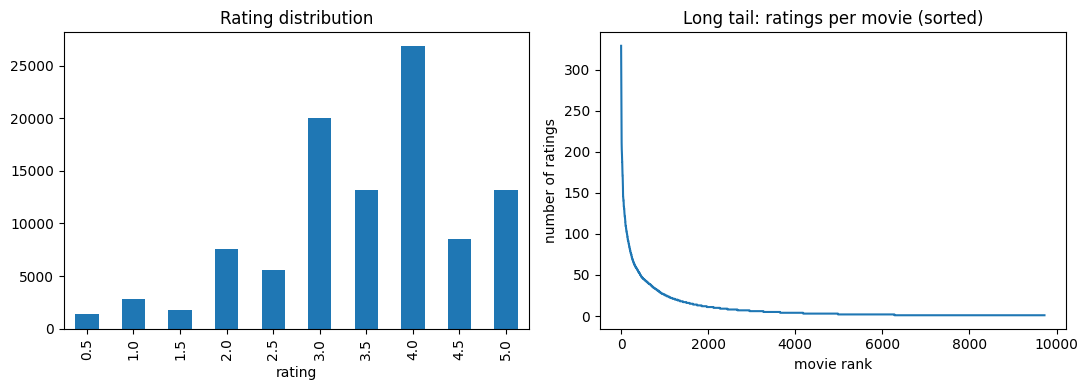

movies with <5 ratings: 6074 of 9724


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.rating.value_counts().sort_index().plot.bar(ax=ax[0])
ax[0].set_title('Rating distribution'); ax[0].set_xlabel('rating')

per_item = df.groupby('item').size().sort_values(ascending=False).values
ax[1].plot(per_item)
ax[1].set_title('Long tail: ratings per movie (sorted)')
ax[1].set_xlabel('movie rank'); ax[1].set_ylabel('number of ratings')
plt.tight_layout(); plt.show()
print('movies with <5 ratings:', int((per_item < 5).sum()), 'of', len(per_item))

## 4. Baselines
TODO: global mean, user mean, most popular. **Split first**, then compute them from train only. These set the bar every model must beat.

In [23]:
all_users = sorted(df.user.unique())
all_items = sorted(df.item.unique())

train, test = split_ratings(df, time_col='time')   # honest, time-based
train_r, test_r = split_ratings(df)                # random, for the twist comparison
print('time split  -> train', len(train), 'test', len(test))
print('random split-> train', len(train_r), 'test', len(test_r))

R_train = to_matrix(train, users=all_users, items=all_items)
gmean     = train.rating.mean()
user_mean = train.groupby('user').rating.mean()

# Rating prediction (RMSE)
pred_global = np.full(len(test), gmean)
pred_user   = test.user.map(user_mean).fillna(gmean).values   # users missing from train fall back to global mean
rmse_global = rmse(pred_global, test.rating)
rmse_user   = rmse(pred_user,   test.rating)
print('RMSE global mean:', round(rmse_global, 3))
print('RMSE user mean  :', round(rmse_user, 3))

# Most popular (top-N): every user gets the same popularity ranking
pop = train.groupby('item').size().reindex(all_items).fillna(0)
pop_scores = pd.DataFrame(np.tile(pop.values, (len(all_users), 1)),
                          index=all_users, columns=all_items)
res_pop = evaluate_topn(pop_scores, train, test, k=10)
print('Most popular:', res_pop)

time split  -> train 80672 test 20164
random split-> train 80672 test 20164
RMSE global mean: 1.069
RMSE user mean  : 0.966
Most popular: {'users': 591, 'precision@10': 0.05736040609137057, 'recall@10': 0.05059450464515492, 'ndcg@10': 0.07572659734118319}


## 5. Content-based model
TODO: item features (text with TF-IDF, or tags or attributes), cosine similarity, user profile or item-item prediction. Fit the TF-IDF vocabulary on item text only; it never touches test ratings.

In [22]:
# --- Section 5: Content-based ---
# 1) item text = genres + all user tags for that movie
movies['genres_clean'] = (movies.genres.str.replace('|', ' ', regex=False)
                                       .str.replace('(no genres listed)', '', regex=False))
tag_text = tags.groupby('movieId').tag.apply(lambda s: ' '.join(s.astype(str).str.lower()))
movies['text'] = movies.genres_clean + ' ' + movies.movieId.map(tag_text).fillna('')
items_df = movies.set_index('movieId').reindex(all_items)      # rows aligned with all_items
items_df['text'] = items_df.text.fillna('')

# 2) TF-IDF fitted on item text only (never on ratings)
tfidf = TfidfVectorizer(stop_words='english')
T = tfidf.fit_transform(items_df.text)                         # items x words (sparse)
print('TF-IDF shape:', T.shape)

# 3) user profile = sum of item vectors weighted by (rating - user mean), TRAIN only
means_tr = R_train.mean(axis=1)
C = R_train.sub(means_tr, axis=0).fillna(0).values             # users x items, unrated = 0 ("no opinion")
P = (T.T @ C.T).T                                              # users x words
cb_scores = pd.DataFrame(cosine_similarity(P, T), index=all_users, columns=all_items)

res_cb = evaluate_topn(cb_scores, train, test, k=10)
print('Content-based:', res_cb)

TF-IDF shape: (9724, 1673)
Content-based: {'users': 591, 'precision@10': 0.005752961082910322, 'recall@10': 0.006144848587028272, 'ndcg@10': 0.007115751273141318}


## 6. Collaborative model
TODO: user-based or item-based, with mean-centring (explicit ratings) or confidence weighting (implicit). Unrated cells are *no opinion*, not zero ratings. Report the effect of k.

In [24]:
from scipy import sparse

def item_sim_cf(R, shrink=10):
    """Item-item cosine on the USER-MEAN-CENTRED matrix (unrated = 0 AFTER centring = 'no opinion').
    shrink > 0 down-weights similarities that rest on few co-raters: sim * n/(n+shrink)."""
    Rv = R.values
    mask = ~np.isnan(Rv)
    C = np.where(mask, Rv - R.mean(axis=1).values[:, None], 0).astype(np.float32)
    norms = np.sqrt((C ** 2).sum(axis=0)); norms[norms == 0] = 1
    S = C.T @ C
    S /= norms[:, None]; S /= norms[None, :]
    if shrink:
        M = mask.astype(np.float32)
        nc = M.T @ M
        S *= nc / (nc + shrink)
        del nc
    S[S < 0] = 0                     # keep positive similarities only
    np.fill_diagonal(S, 0)
    return S

def item_sim_content(T, chunk=1000):
    """Item-item cosine from TF-IDF text (rows of T are L2-normalised, so dot product = cosine). Uses no ratings."""
    n = T.shape[0]
    S = np.zeros((n, n), dtype=np.float32)
    for a in range(0, n, chunk):
        S[a:a + chunk] = (T[a:a + chunk] @ T.T).toarray()
    np.fill_diagonal(S, 0)
    return S

def topk_sparse(S, k, chunk=1000):
    """Keep only the k largest similarities in every row."""
    n = S.shape[0]
    rr, cc, vv = [], [], []
    for a in range(0, n, chunk):
        blk = S[a:a + chunk]
        idx = np.argpartition(-blk, k, axis=1)[:, :k]
        rr.append(np.repeat(np.arange(a, a + blk.shape[0]), k))
        cc.append(idx.ravel())
        vv.append(np.take_along_axis(blk, idx, axis=1).ravel())
    Sk = sparse.csr_matrix((np.concatenate(vv), (np.concatenate(rr), np.concatenate(cc))), shape=S.shape)
    Sk.eliminate_zeros()
    return Sk

def neighbourhood(R, S, k=None, means=None):
    """pred[u,i] = mean_u + sum_j S[i,j]*(r_uj - mean_u) / sum_j |S[i,j]|
    j runs over the k items most similar to i (all items if k is None) that user u HAS rated.
    Returns (pred, num). pred is NaN where u rated none of i's neighbours. num is the un-normalised numerator."""
    Rv = R.values
    mask = ~np.isnan(Rv)
    mu = R.mean(axis=1).values if means is None else np.asarray(means, dtype=float)
    C = np.where(mask, Rv - mu[:, None], 0).astype(np.float32)
    M = mask.astype(np.float32)
    if k is None:
        num = C @ S.T
        den = M @ np.abs(S).T
    else:
        Sk = topk_sparse(S, k)
        num = (Sk @ C.T).T
        den = (abs(Sk) @ M.T).T
    with np.errstate(divide='ignore', invalid='ignore'):
        pred = np.where(den > 1e-9, mu[:, None] + num / den, np.nan)
    return (pd.DataFrame(pred, index=R.index, columns=R.columns),
            pd.DataFrame(num, index=R.index, columns=R.columns))

def fill_user_mean(pred, means):
    """Where a model cannot score a cell (NaN), fall back to that user's mean rating."""
    arr = pred.values
    return pd.DataFrame(np.where(np.isnan(arr), np.asarray(means, dtype=float)[:, None], arr),
                        index=pred.index, columns=pred.columns)

# content similarity depends on text only, so it is computed once and reused everywhere
S_cb = item_sim_content(T)

# choose k and shrinkage on a VALIDATION split taken from train (test untouched)
train_sub, val = split_ratings(train, time_col='time')
R_sub = to_matrix(train_sub, users=all_users, items=all_items)
means_sub = R_sub.mean(axis=1)

cf_val = {}
for shrink in [0, 10]:
    S_sub = item_sim_cf(R_sub, shrink=shrink)
    for k in [5, 10, 20, 50, 100]:
        p, _ = neighbourhood(R_sub, S_sub, k)
        cf_val[(shrink, k)] = rmse_from_scores(fill_user_mean(p, means_sub), val)
        print(f'shrink={shrink:>2}  k={k:>3}  validation RMSE = {cf_val[(shrink, k)]:.3f}')
best_shrink, best_k_cf = min(cf_val, key=cf_val.get)
print('chosen: shrink =', best_shrink, ', k =', best_k_cf)

# refit on the full train, evaluate once on test
S_cf = item_sim_cf(R_train, shrink=best_shrink)
means_tr = R_train.mean(axis=1)
pred_cf_raw, num_cf = neighbourhood(R_train, S_cf, best_k_cf)
pred_cf = fill_user_mean(pred_cf_raw, means_tr)
rmse_cf = rmse_from_scores(pred_cf, test)
rows_t, cols_t = test.user.map(u_idx).values, test.item.map(i_idx).values
print('item-CF test RMSE:', round(rmse_cf, 3),
      '| share of test ratings CF could really score:', round(float(np.mean(~np.isnan(pred_cf_raw.values[rows_t, cols_t]))), 3))

shrink= 0  k=  5  validation RMSE = 0.956
shrink= 0  k= 10  validation RMSE = 0.964
shrink= 0  k= 20  validation RMSE = 0.971
shrink= 0  k= 50  validation RMSE = 0.973
shrink= 0  k=100  validation RMSE = 0.963
shrink=10  k=  5  validation RMSE = 0.988
shrink=10  k= 10  validation RMSE = 0.984
shrink=10  k= 20  validation RMSE = 0.969
shrink=10  k= 50  validation RMSE = 0.934
shrink=10  k=100  validation RMSE = 0.916
chosen: shrink = 10 , k = 100
item-CF test RMSE: 0.916 | share of test ratings CF could really score: 0.874


## 7. Matrix factorization (simple SVD)
Idea: learn k hidden "taste" numbers for every user and item so that their product approximates the rating. Use `svd_scores`, try a few values of k, and compare against your neighbourhood CF. In two sentences, say how this differs from neighbourhood CF.

In [25]:
# --- Section 7: Matrix factorization (simple SVD) ---
u_idx = {u: i for i, u in enumerate(all_users)}
i_idx = {m: i for i, m in enumerate(all_items)}

def rmse_from_scores(sc, df_eval):
    """RMSE of a users x items score table on the (user, item, rating) rows of df_eval."""
    rows = df_eval.user.map(u_idx).values
    cols = df_eval.item.map(i_idx).values
    pred = np.clip(sc.values[rows, cols], 0.5, 5)      # ratings live in [0.5, 5]
    return rmse(pred, df_eval.rating)

# 1) choose k on a validation split taken from TRAIN only (test is untouched)
train_sub, val = split_ratings(train, time_col='time')
R_sub = to_matrix(train_sub, users=all_users, items=all_items)

val_rmse = {}
for k in [5, 10, 20, 50]:
    sc = svd_scores(R_sub, k=k)
    val_rmse[k] = rmse_from_scores(sc, val)
    print(f'k={k:>2}  validation RMSE = {val_rmse[k]:.3f}')
best_k = min(val_rmse, key=val_rmse.get)
print('best k on validation:', best_k)

# 2) refit on the full train with that k, evaluate once on test
sc_svd = svd_scores(R_train, k=best_k)
rmse_svd = rmse_from_scores(sc_svd, test)
res_svd = evaluate_topn(sc_svd, train, test, k=10)
print(f'SVD (k={best_k}) test RMSE:', round(rmse_svd, 3))
print('SVD top-10:', res_svd)



k= 5  validation RMSE = 0.933
k=10  validation RMSE = 0.933
k=20  validation RMSE = 0.935
k=50  validation RMSE = 0.941
best k on validation: 5
SVD (k=5) test RMSE: 0.945
SVD top-10: {'users': 591, 'precision@10': 0.06954314720812182, 'recall@10': 0.04884648700272789, 'ndcg@10': 0.08260056135795533}


## 8. Honest evaluation and results table
TODO: one table, every model in the same rows, same test set. Use RMSE (explicit data) **and** precision@k, recall@k and NDCG@k (`evaluate_topn`). Include baselines. If you have timestamps, use the time-based split and say so. Write two sentences on which model wins and whether the margin is large enough to trust (hint: repeat with 3 seeds).

| Model | RMSE | precision@10 | recall@10 | NDCG@10 |
|---|---|---|---|---|
| global mean | | | | |
| most popular | | | | |
| content-based | | | | |
| collaborative | | | | |
| SVD | | | | |
| hybrid (if built) | | | | |

In [26]:
def coverage_at_k(scores, train_, k=10):
    """Share of the catalogue that appears in anybody's top-k (already-rated items excluded)."""
    arr = scores.values.astype(np.float32)
    arr[train_.user.map(u_idx).values, train_.item.map(i_idx).values] = -np.inf
    top = np.argpartition(-arr, k, axis=1)[:, :k]
    return len(np.unique(top)) / arr.shape[1]

def run_pipeline(train_, test_, k_cf, k_svd, shrink):
    """Fits every model on train_ ONLY and scores it on test_. Returns (results table, artefacts)."""
    R = to_matrix(train_, users=all_users, items=all_items)
    means = R.mean(axis=1)
    gm = train_.rating.mean()
    um = train_.groupby('user').rating.mean()
    # baselines
    r_global = rmse(np.full(len(test_), gm), test_.rating)
    r_user = rmse(test_.user.map(um).fillna(gm).values, test_.rating)
    cnt = train_.groupby('item').size().reindex(all_items).fillna(0).values
    pop_sc = pd.DataFrame(np.tile(cnt, (len(all_users), 1)), index=all_users, columns=all_items)
    # content-based: ratings via text-similar rated items; top-N via mean-centred user profile
    cb_raw, _ = neighbourhood(R, S_cb, None)
    r_cb = rmse_from_scores(fill_user_mean(cb_raw, means), test_)
    Cm = R.sub(means, axis=0).fillna(0).values
    cb_sc = pd.DataFrame(cosine_similarity((T.T @ Cm.T).T, T), index=all_users, columns=all_items)
    # item-based CF
    S = item_sim_cf(R, shrink=shrink)
    cf_raw, num = neighbourhood(R, S, k_cf)
    cf_f = fill_user_mean(cf_raw, means)
    r_cf = rmse_from_scores(cf_f, test_)
    # SVD
    sc_svd_ = svd_scores(R, k=k_svd)
    r_svd = rmse_from_scores(sc_svd_, test_)

    def row(rm, scores):
        if scores is None:
            return {'RMSE': rm, 'precision@10': np.nan, 'recall@10': np.nan, 'ndcg@10': np.nan, 'coverage@10': np.nan}
        r = evaluate_topn(scores, train_, test_, k=10)
        return {'RMSE': rm, 'precision@10': r['precision@10'], 'recall@10': r['recall@10'],
                'ndcg@10': r['ndcg@10'], 'coverage@10': coverage_at_k(scores, train_, 10)}

    table = pd.DataFrame({'global mean': row(r_global, None), 'user mean': row(r_user, None),
                          'most popular': row(np.nan, pop_sc), 'content-based': row(r_cb, cb_sc),
                          'item-CF (centred)': row(r_cf, num), 'SVD': row(r_svd, sc_svd_)}).T
    art = {'R': R, 'means': means, 'cf_raw': cf_raw, 'num_cf': num, 'cb_raw': cb_raw, 'cb_scores': cb_sc, 'sc_svd': sc_svd_,
           'ndcg_cf_normalised': evaluate_topn(cf_f, train_, test_, k=10)['ndcg@10']}
    return table, art

table_time, art = run_pipeline(train, test, best_k_cf, best_k, best_shrink)
print('TIME-BASED split (each user\'s latest 20% = test)')
print(table_time.round(3).to_string())
print('\nndcg@10 of item-CF if ranked by normalised predicted rating instead of raw weighted sum:', round(art['ndcg_cf_normalised'], 4))


TIME-BASED split (each user's latest 20% = test)
                    RMSE  precision@10  recall@10  ndcg@10  coverage@10
global mean        1.069           NaN        NaN      NaN          NaN
user mean          0.966           NaN        NaN      NaN          NaN
most popular         NaN         0.057      0.051    0.076        0.010
content-based      0.936         0.006      0.006    0.007        0.334
item-CF (centred)  0.916         0.083      0.073    0.106        0.074
SVD                0.945         0.070      0.049    0.083        0.032

ndcg@10 of item-CF if ranked by normalised predicted rating instead of raw weighted sum: 0.0009


## 9. Cold start or hybrid
TODO: pick one (both is better). **Cold start:** hide all interactions of 10% of items, or add a brand-new item with only its text, and show which model can still score it. **Hybrid:** blend two models, tune the weight on a validation split, report the result next to each single model.

In [27]:
def blend(cf_raw, cb_raw, means, a):
    """a * CF + (1-a) * content. If CF cannot score a cell it falls back to content, then to the user mean."""
    m = np.asarray(means, dtype=float)[:, None]
    cb = np.where(np.isnan(cb_raw.values), m, cb_raw.values)
    cf = np.where(np.isnan(cf_raw.values), cb, cf_raw.values)
    return pd.DataFrame(a * cf + (1 - a) * cb, index=cf_raw.index, columns=cf_raw.columns)

def zrow(d):
    a = d.values
    return pd.DataFrame((a - a.mean(1, keepdims=True)) / (a.std(1, keepdims=True) + 1e-9), index=d.index, columns=d.columns)

# 9a) tune the blend weight alpha on the validation split (train only)
S_sub = item_sim_cf(R_sub, shrink=best_shrink)
cf_sub_raw, _ = neighbourhood(R_sub, S_sub, best_k_cf)
cb_sub_raw, _ = neighbourhood(R_sub, S_cb, None)
alpha_val = {a: rmse_from_scores(blend(cf_sub_raw, cb_sub_raw, means_sub, a), val) for a in [0, 0.25, 0.5, 0.75, 1]}
for a, v in alpha_val.items():
    print(f'alpha={a:<4} validation RMSE = {v:.3f}')
best_alpha = min(alpha_val, key=alpha_val.get)
print('best alpha:', best_alpha)

# 9b) hybrid on the test set (models already fitted on train only)
hyb_pred = blend(art['cf_raw'], art['cb_raw'], art['means'], best_alpha)
rmse_hyb = rmse_from_scores(hyb_pred, test)
hybrid_scores = best_alpha * zrow(art['num_cf']) + (1 - best_alpha) * zrow(art['cb_scores'])   # for top-N
res_hyb = evaluate_topn(hybrid_scores, train, test, k=10)
table_time.loc['hybrid'] = {'RMSE': rmse_hyb, 'precision@10': res_hyb['precision@10'], 'recall@10': res_hyb['recall@10'],
                            'ndcg@10': res_hyb['ndcg@10'], 'coverage@10': coverage_at_k(hybrid_scores, train, 10)}
print(table_time.round(3).to_string())

# 9c) cold-start simulation: hide ALL training ratings of 10% of the movies
rng = np.random.RandomState(1)
cnt_items = df.groupby('item').size()
eligible = cnt_items[cnt_items >= 10].index.values
cold_items = rng.choice(eligible, size=int(0.1 * len(eligible)), replace=False)
train_c = train[~train.item.isin(cold_items)]
test_c = test[test.item.isin(cold_items)]
print('cold items:', len(cold_items), '| cold test ratings:', len(test_c))

R_c = to_matrix(train_c, users=all_users, items=all_items)
m_c = R_c.mean(axis=1)
S_cf_c = item_sim_cf(R_c, shrink=best_shrink)
cf_c_raw, _ = neighbourhood(R_c, S_cf_c, best_k_cf)
cb_c_raw, _ = neighbourhood(R_c, S_cb, None)
r_c, c_c = test_c.user.map(u_idx).values, test_c.item.map(i_idx).values
print('share of cold ratings CF can score:', round(float(np.mean(~np.isnan(cf_c_raw.values[r_c, c_c]))), 3),
      '| content-based can score:', round(float(np.mean(~np.isnan(cb_c_raw.values[r_c, c_c]))), 3))
cold = pd.Series({
    'global mean': rmse(np.full(len(test_c), train_c.rating.mean()), test_c.rating),
    'CF only (falls back to user mean)': rmse_from_scores(fill_user_mean(cf_c_raw, m_c), test_c),
    'content-based': rmse_from_scores(fill_user_mean(cb_c_raw, m_c), test_c),
    'hybrid (content when CF cannot score)': rmse_from_scores(blend(cf_c_raw, cb_c_raw, m_c, best_alpha), test_c)})
print('\nRMSE on COLD items only:'); print(cold.round(3).to_string())


alpha=0    validation RMSE = 0.923
alpha=0.25 validation RMSE = 0.894
alpha=0.5  validation RMSE = 0.883
alpha=0.75 validation RMSE = 0.888
alpha=1    validation RMSE = 0.911
best alpha: 0.5
                    RMSE  precision@10  recall@10  ndcg@10  coverage@10
global mean        1.069           NaN        NaN      NaN          NaN
user mean          0.966           NaN        NaN      NaN          NaN
most popular         NaN         0.057      0.051    0.076        0.010
content-based      0.936         0.006      0.006    0.007        0.334
item-CF (centred)  0.916         0.083      0.073    0.106        0.074
SVD                0.945         0.070      0.049    0.083        0.032
hybrid             0.889         0.083      0.073    0.108        0.082
cold items: 226 | cold test ratings: 1378
share of cold ratings CF can score: 0.0 | content-based can score: 1.0

RMSE on COLD items only:
global mean                              1.012
CF only (falls back to user mean)        0.940


## 10. Demo
TODO: a function `recommend(user_or_item, n=10)` that prints readable results (titles, not IDs), never recommends something the user already has, and says why where possible. Optional upgrade: wrap it in Streamlit.

In [28]:
title_of = movies.set_index('movieId').title.to_dict()
genres_of = movies.set_index('movieId').genres.to_dict()
pop_full = df.groupby('item').agg(cnt=('rating', 'size'), avg=('rating', 'mean'))

def recommend(user, n=10, scores=None):
    """Top-n unseen movies for a user, with titles, genres and a reason. New users get a popularity fallback."""
    scores = hybrid_scores if scores is None else scores
    if user not in scores.index:
        pf = pop_full[pop_full.cnt >= 50].sort_values('avg', ascending=False).head(n)
        print(f'User {user} has no ratings -> popularity fallback (best-rated movies with 50+ ratings):')
        for i, r in pf.iterrows():
            print(f'  {title_of[i]} | {genres_of[i]} | avg {r.avg:.2f} from {int(r.cnt)} ratings')
        return
    seen = set(df.loc[df.user == user, 'item'])                 # everything the user ever rated
    s = scores.loc[user].drop(labels=[i for i in seen if i in scores.columns])
    top = s.sort_values(ascending=False).head(n).index
    liked = df[(df.user == user) & (df.rating >= 4)].item.values
    print(f'Top {n} for user {user} (has rated {len(seen)} movies):')
    for rank, i in enumerate(top, 1):
        why = ''
        if len(liked):
            j = liked[int(np.argmax(S_cb[i_idx[i], [i_idx[x] for x in liked]]))]
            why = f'  <- because you liked "{title_of[j]}"'
        print(f'{rank:>2}. {title_of[i]} | {genres_of[i]}{why}')

recommend(all_users[0], n=5)

Top 5 for user 1 (has rated 232 movies):
 1. Godfather, The (1972) | Crime|Drama  <- because you liked "Goodfellas (1990)"
 2. Godfather: Part II, The (1974) | Crime|Drama  <- because you liked "Goodfellas (1990)"
 3. Departed, The (2006) | Crime|Drama|Thriller  <- because you liked "Game, The (1997)"
 4. Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964) | Comedy|War  <- because you liked "Very Bad Things (1998)"
 5. Peter Pan (1953) | Animation|Children|Fantasy|Musical  <- because you liked "James and the Giant Peach (1996)"


## 11. Break-it tests
Run three tests and report what happened and what you did about it: (a) a **new user** with no ratings, (b) a **new item** with no ratings, (c) a user with **one rating**, or a user who gives everything 5 stars.

In [29]:
# (a) brand-new user
recommend(999999, n=5)

# (b) brand-new item: only its text is known. CF has no ratings for it (see the cold-start result in Section 9).
new_text = 'sci-fi space adventure aliens action thriller'
sims = cosine_similarity(tfidf.transform([new_text]), T).ravel()
print('\nNew movie described as:', new_text, '\nMost similar existing movies (content-based can place it, CF cannot):')
for j in np.argsort(-sims)[:5]:
    print(f'  {title_of[all_items[j]]} | {genres_of[all_items[j]]} | similarity {sims[j]:.3f}')

# (c) a user with ONE rating, and a user who gives everything 5 stars
def profile_top(ratings_dict, centre='user', n=5):
    r = pd.Series(ratings_dict, dtype=float)
    r = r[[m for m in r.index if m in i_idx]]
    w = r - (r.mean() if centre == 'user' else train.rating.mean())
    p = np.asarray(T[[i_idx[m] for m in r.index]].T @ w.values).ravel()
    s = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=all_items).drop(labels=list(r.index))
    return float(np.abs(p).sum()), s.sort_values(ascending=False).head(n)

for name, rd in {'one rating': {all_items[0]: 5}, 'all 5 stars': {all_items[0]: 5, all_items[1]: 5, all_items[2]: 5}}.items():
    mass, top = profile_top(rd, 'user')
    print(f'\n[{name}] centred on the user\'s own mean -> profile size = {mass:.4f} (0 means no information)')
    mass2, top2 = profile_top(rd, 'global')
    print(f'[{name}] fix: centre on the global mean   -> profile size = {mass2:.4f}; top picks:',
          [title_of[i] for i in top2.index[:3]])


User 999999 has no ratings -> popularity fallback (best-rated movies with 50+ ratings):
  Shawshank Redemption, The (1994) | Crime|Drama | avg 4.43 from 317 ratings
  Godfather, The (1972) | Crime|Drama | avg 4.29 from 192 ratings
  Fight Club (1999) | Action|Crime|Drama|Thriller | avg 4.27 from 218 ratings
  Cool Hand Luke (1967) | Drama | avg 4.27 from 57 ratings
  Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964) | Comedy|War | avg 4.27 from 97 ratings

New movie described as: sci-fi space adventure aliens action thriller 
Most similar existing movies (content-based can place it, CF cannot):
  Independence Day (a.k.a. ID4) (1996) | Action|Adventure|Sci-Fi|Thriller | similarity 0.805
  Arrival, The (1996) | Action|Sci-Fi|Thriller | similarity 0.767
  Aliens (1986) | Action|Adventure|Horror|Sci-Fi | similarity 0.761
  Armageddon (1998) | Action|Romance|Sci-Fi|Thriller | similarity 0.732
  Day the Earth Stood Still, The (1951) | Drama|Sci-Fi|Thriller | similar

## 12. By-hand check
Pick one prediction from your collaborative model. Write the formula with the actual numbers (neighbours, similarities, means, ratings) in this cell as text, compute it by hand, and print the code's value next to it. They should match up to rounding.

In [30]:
# Same neighbour rule as the model: item i's k most similar items, and only those the user rated contribute.
Sk = topk_sparse(S_cf, best_k_cf)
Rv_tr = R_train.values
chosen = None
for u, i, r_actual in test.sample(frac=1, random_state=3)[['user', 'item', 'rating']].itertuples(index=False):
    nb = Sk.getrow(i_idx[i])
    used = [(j, s_) for j, s_ in zip(nb.indices, nb.data) if not np.isnan(Rv_tr[u_idx[u], j])]
    if 3 <= len(used) <= 5:
        chosen = (u, i, r_actual, used); break
u, i, actual, used = chosen
mu_u = means_tr[u]
print(f'User {u}, movie "{title_of[i]}"  | user mean = {mu_u:.4f}  | actual rating = {actual}\n')
tab = pd.DataFrame([{'neighbour movie': title_of[all_items[j]], 'similarity s': s_, 'user rating r': Rv_tr[u_idx[u], j],
                     'centred (r - mean)': Rv_tr[u_idx[u], j] - mu_u, 's * centred': s_ * (Rv_tr[u_idx[u], j] - mu_u)} for j, s_ in used])
print(tab.round(4).to_string(index=False))
num_h = tab['s * centred'].sum(); den_h = tab['similarity s'].abs().sum()
by_hand = mu_u + num_h / den_h
print(f'\nformula: pred = mean + sum(s * centred) / sum(|s|)')
print(f'       = {mu_u:.4f} + ({num_h:.4f}) / ({den_h:.4f})')
print(f'       = {by_hand:.4f}   <- by hand')
print(f'code   = {pred_cf_raw.loc[u, i]:.4f}   <- pred_cf_raw from Section 6')
print('difference:', abs(by_hand - pred_cf_raw.loc[u, i]))


User 91, movie "Deep Rising (1998)"  | user mean = 3.5163  | actual rating = 2.5

    neighbour movie  similarity s  user rating r  centred (r - mean)  s * centred
     Jumanji (1995)         0.035            3.0              -0.516   -1.790e-02
 Judge Dredd (1995)         0.030            3.5              -0.016   -5.000e-04
 Mystery Men (1999)         0.048            3.5              -0.016   -8.000e-04
Animal House (1978)         0.031            3.5              -0.016   -5.000e-04

formula: pred = mean + sum(s * centred) / sum(|s|)
       = 3.5163 + (-0.0197) / (0.1434)
       = 3.3788   <- by hand
code   = 3.3788   <- pred_cf_raw from Section 6
difference: 2.2064954308120832e-09


## 13. Understanding pack
**13a. Deliberate-leak experiment.** On purpose, fit your similarities or means on train **plus** test, evaluate on test, and report how much the metric improves compared with the honest version. This shows you know what leakage looks like. Result: ______ (honest) vs ______ (leaky).

In [31]:
R_full = to_matrix(df, users=all_users, items=all_items)            # train + TEST ratings: this is the mistake
means_full = R_full.mean(axis=1)
S_leak = item_sim_cf(R_full, shrink=best_shrink)                    # similarities see the test ratings
p_leak_raw, num_leak = neighbourhood(R_train, S_leak, best_k_cf, means=means_full)
rmse_leak = rmse_from_scores(fill_user_mean(p_leak_raw, means_full), test)
ndcg_leak = evaluate_topn(num_leak, train, test, k=10)['ndcg@10']
rmse_hon, ndcg_hon = table_time.loc['item-CF (centred)', 'RMSE'], table_time.loc['item-CF (centred)', 'ndcg@10']
print(f'RMSE    honest {rmse_hon:.3f}  vs leaky {rmse_leak:.3f}  ({100 * (rmse_leak / rmse_hon - 1):+.1f}%)')
print(f'NDCG@10 honest {ndcg_hon:.4f} vs leaky {ndcg_leak:.4f}  ({100 * (ndcg_leak / max(ndcg_hon, 1e-9) - 1):+.1f}%)')

# Twist: random split vs time-based split
table_rand, _ = run_pipeline(train_r, test_r, best_k_cf, best_k, best_shrink)
cmp_ = pd.DataFrame({'RMSE (time)': table_time.RMSE, 'RMSE (random)': table_rand.RMSE,
                     'NDCG@10 (time)': table_time['ndcg@10'], 'NDCG@10 (random)': table_rand['ndcg@10']})
cmp_['NDCG overstated by %'] = 100 * (cmp_['NDCG@10 (random)'] / cmp_['NDCG@10 (time)'] - 1)
print('\nRandom vs time-based split (same models, same hyper-parameters):')
print(cmp_.round(3).to_string())


RMSE    honest 0.916  vs leaky 0.601  (-34.4%)
NDCG@10 honest 0.1063 vs leaky 0.1999  (+88.1%)

Random vs time-based split (same models, same hyper-parameters):
                   RMSE (time)  RMSE (random)  NDCG@10 (time)  NDCG@10 (random)  NDCG overstated by %
SVD                      0.945          0.911           0.083             0.152                84.571
content-based            0.936          0.914           0.007             0.009                23.231
global mean              1.069          1.041             NaN               NaN                   NaN
hybrid                   0.889            NaN           0.108               NaN                   NaN
item-CF (centred)        0.916          0.871           0.106             0.203                90.519
most popular               NaN            NaN           0.076             0.162               114.477
user mean                0.966          0.942             NaN               NaN                   NaN


**13b. Decision log** (at least 5)

| Decision | Alternatives I tried | Evidence (a number) | Chosen |
|---|---|---|---|

**13c. Bug log** (at least 2 real problems)

| What went wrong | How I found it | Fix | Before and after |
|---|---|---|---|
| | | | |
| | | | |

## 14. AI-use log
| Task | Tool | What the AI produced | What I checked or changed |
|---|---|---|---|
| | | | |
| | | | |

**One thing the AI got wrong (and how I caught it):**

**What I would do with 100 times more data:**

**How industry systems extend this project:**

---
## README template (copy into README.md)
```
# <Project title>
One-line summary: <what it recommends, on what data, best result vs baseline>

## Problem
## Data (source, licence, size, sparsity)
## Method (content-based, collaborative, SVD, hybrid; how you split)
## Results (the table from Section 8, plus a screenshot of the demo)
## Understanding pack (by-hand check, deliberate-leak result, break-it findings)
## Limitations
## AI-use note (what AI helped with, what you verified)
## How to run (Colab link or commands)
```